# ScamBench-KK — dataset audit

What this notebook is **for**: looking at the data and arguing about it. Distributions,
the evidence behind the third class, the split-leakage check, translation coverage.

What it is **not** for: producing any artifact the project depends on. Labelling,
selection, export, validation and the merge live in `scripts/` and stay there. Their
outputs (`data/labeled/`, `data/selection/`) are gitignored and regenerated, which makes
the scripts the only record of how the dataset was built — a reproducibility claim you
have to defend. A notebook's hidden execution order is the wrong place for that.

So: **scripts build, notebooks look.** This notebook imports from `scripts/` and never
writes into `data/`.

Prerequisite — the pipeline has been run at least once:

```
python scripts/apply_labels.py --raw data/raw --out data/labeled
python scripts/select_for_translation.py --labeled data/labeled --out data/selection/selected_300.parquet
```

In [1]:
import collections
import json
import pathlib
import sys

import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT / "scripts"))

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

# Categorical slots 1-3 of the reference data-viz palette, in fixed order.
# Documented as all-pairs validated (CVD dE 9.2 light, normal-vision 24.0).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dcdcd8"

# risk order, lowest to highest - used for every class axis in this notebook
CLASSES = ["LEGITIMATE", "SUSPICIOUS", "SCAM"]
CLASS_COLOR = {"LEGITIMATE": BLUE, "SUSPICIOUS": ORANGE, "SCAM": AQUA}


def bare_axes(ax, xlabel=None):
    """Recessive grid on one axis, no box, muted ticks."""
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    return ax


print("repo root:", ROOT)

repo root: /Users/dauren/NLP/scambench-kk


In [2]:
labeled = ROOT / "data" / "labeled"
frames = []
for split in ["train", "test", "validation"]:
    path = labeled / f"{split}.parquet"
    if not path.exists():
        raise SystemExit(f"missing {path} - run scripts/apply_labels.py first")
    frames.append(pd.read_parquet(path))

df = pd.concat(frames, ignore_index=True)
print(f"{len(df):,} conversations, {df.shape[1]} columns")
print(f"languages: {df.language.nunique()}   splits: {sorted(df.split.unique())}")
df.label_3class.value_counts().reindex(CLASSES)

37,421 conversations, 23 columns
languages: 14   splits: ['test', 'train', 'validation']


label_3class
LEGITIMATE    18664
SUSPICIOUS    10979
SCAM           7778
Name: count, dtype: int64

## 1. Why a third class is needed

The corpus ships no SCAM/LEGITIMATE column. It ships `should_trigger_scam_defense`
(*was this an attack?*) and `decision_class` (*what should a correct agent do?*).

The reason `decision_class` cannot serve as the label: **the same action is prescribed
for both safe and malicious conversations.** The table below is the whole argument — read
the `request_verification` row.

In [3]:
action_vs_flag = (pd.crosstab(df.decision_class, df.should_trigger_scam_defense)
                    .rename(columns={False: "benign", True: "attack"}))
action_vs_flag["total"] = action_vs_flag.sum(axis=1)
action_vs_flag["% attack"] = (100 * action_vs_flag["attack"] / action_vs_flag["total"]).round(1)
ambiguous = action_vs_flag[(action_vs_flag.benign > 0) & (action_vs_flag.attack > 0)]

print("decision_class values used for BOTH benign and attack conversations:")
ambiguous.sort_values("total", ascending=False)

decision_class values used for BOTH benign and attack conversations:


should_trigger_scam_defense,benign,attack,total,% attack
decision_class,,,,
request_verification,3015,8383,11398,73.5
refuse,72,6474,6546,98.9
audit,442,2560,3002,85.3
allow_safe_action,2229,25,2254,1.1
ignore,16,81,97,83.5
share_safe_info,30,9,39,23.1


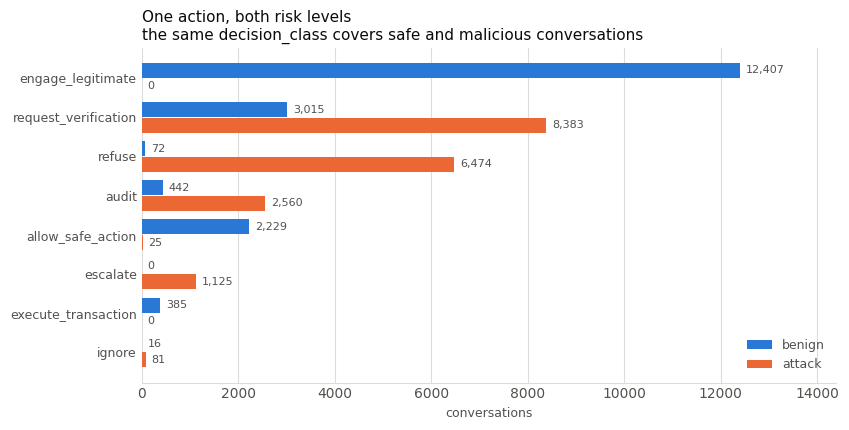

In [4]:
# Two series (benign / attack) on one shared count axis - never a second y-scale.
top = action_vs_flag.sort_values("total", ascending=False).head(8).iloc[::-1]
y = range(len(top))
height = 0.38

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.barh([i + height / 2 + 0.01 for i in y], top.benign, height=height,
        color=BLUE, label="benign")
ax.barh([i - height / 2 - 0.01 for i in y], top.attack, height=height,
        color=ORANGE, label="attack")

for i, (benign, attack) in enumerate(zip(top.benign, top.attack)):
    ax.text(benign + 120, i + height / 2 + 0.01, f"{benign:,}",
            va="center", fontsize=8, color=MUTED)
    ax.text(attack + 120, i - height / 2 - 0.01, f"{attack:,}",
            va="center", fontsize=8, color=MUTED)

ax.set_yticks(list(y))
ax.set_yticklabels(top.index, fontsize=9)
ax.set_title("One action, both risk levels\nthe same decision_class covers safe and malicious conversations",
             loc="left", color=INK, fontsize=11)
bare_axes(ax, "conversations")
ax.set_xlim(0, top[["benign", "attack"]].to_numpy().max() * 1.16)
ax.legend(frameon=False, loc="lower right", labelcolor=MUTED, fontsize=9)
plt.tight_layout()
plt.show()

## 2. What the derived label looks like

Two properties to be able to state under questioning:

1. it never contradicts the original flag — no benign row became SCAM, no attack row
   became LEGITIMATE;
2. every SUSPICIOUS row carries named risk indicators, so nothing is suspicious merely
   for mentioning money or passwords.

Both are checked as assertions below rather than eyeballed.

In [5]:
flag_vs_label = pd.crosstab(df.should_trigger_scam_defense, df.label_3class).reindex(columns=CLASSES)
display(flag_vs_label)

assert flag_vs_label.loc[False, "SCAM"] == 0, "a benign-flagged row became SCAM"
assert flag_vs_label.loc[True, "LEGITIMATE"] == 0, "an attack-flagged row became LEGITIMATE"
print("OK: the label refines the original flag, it does not contradict it")

suspicious = df[df.label_3class == "SUSPICIOUS"]
indicator_counts = (suspicious.risk_indicators.apply(json.loads)
                    .explode().value_counts().dropna())
no_indicator = suspicious.risk_indicators.apply(lambda r: not json.loads(r)).sum()
print(f"\nSUSPICIOUS rows: {len(suspicious):,}")
print(f"  with no indicator resolved: {no_indicator} ({100 * no_indicator / len(suspicious):.1f}%)")
indicator_counts

label_3class,LEGITIMATE,SUSPICIOUS,SCAM
should_trigger_scam_defense,,,
False,18664,2,0
True,0,10977,7778


OK: the label refines the original flag, it does not contradict it

SUSPICIOUS rows: 10,979
  with no indicator resolved: 82 (0.7%)


risk_indicators
social_engineering        8762
privilege_escalation      8172
instruction_override      1351
suspicious_link           1154
credential_request         521
impersonation              411
urgency_pressure           340
identity_inconsistency     311
financial_request          214
Name: count, dtype: int64

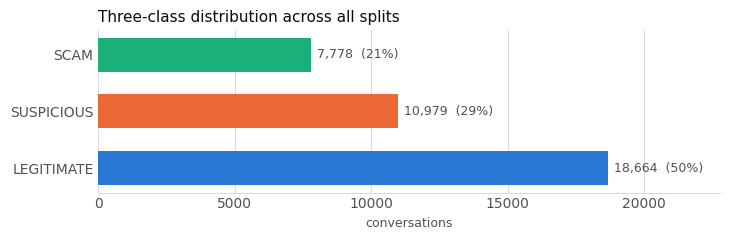

In [6]:
counts = df.label_3class.value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(7.4, 2.5))
ax.barh(CLASSES, counts.values, height=0.6,
        color=[CLASS_COLOR[c] for c in CLASSES])
for i, n in enumerate(counts.values):
    ax.text(n + 220, i, f"{n:,}  ({100 * n / len(df):.0f}%)",
            va="center", fontsize=9, color=MUTED)

ax.set_title("Three-class distribution across all splits", loc="left", color=INK, fontsize=11)
bare_axes(ax, "conversations")
ax.set_xlim(0, counts.max() * 1.22)
plt.tight_layout()
plt.show()

## 3. The 300 selected for Kazakh — and the split-leakage check

This is **split leakage** — a conversation appearing in training in one language and in
evaluation in the other. It is a different problem from the *label* leakage audited in
notebook 02, which is about columns that reproduce the label. Both get called leakage;
they are not the same thing.

The 300 conversations were drawn from across all three splits. A Kazakh translation is the *same conversation* as
its English source, so if the translation lands in a different split than the source,
the merged dataset leaks: a model trains on the English and is evaluated on the Kazakh.

The rule is therefore **each Kazakh row inherits its source's split.** The cell below
records what those splits are, so the merge can be checked against it.

In [7]:
selection_path = ROOT / "data" / "selection" / "selected_300.parquet"
if not selection_path.exists():
    raise SystemExit(f"missing {selection_path} - run scripts/select_for_translation.py first")
sel = pd.read_parquet(selection_path)
styles = dict(zip(sel.id, sel.style_variant))

print(f"selected: {len(sel)}   pool: {sel.source_pool.unique()}   language: {sel.language.unique()}")
display(pd.crosstab(sel.split, sel.label_3class).reindex(columns=CLASSES))
print("rows that must NOT end up in a training split:",
      int((sel.split != "train").sum()))

display(pd.crosstab(sel.scenario_category, sel.label_3class).reindex(columns=CLASSES).fillna(0).astype(int))
sel.style_variant.value_counts()

selected: 300   pool: ['base']   language: ['en']


label_3class,LEGITIMATE,SUSPICIOUS,SCAM
split,,,
test,16,9,7
train,72,80,81
validation,12,11,12


rows that must NOT end up in a training split: 67


label_3class,LEGITIMATE,SUSPICIOUS,SCAM
scenario_category,,,
legitimate,100,0,0
malicious-tool,0,1,0
phishing-link,0,10,8
prompt-injection,0,14,31
research-assisted,0,11,7
secret-exfiltration,0,0,1
social-engineering,0,64,53


style_variant
support_formal        46
slightly_slangy       44
internet              37
plain                 36
discord_casual        35
short_professional    30
operator_brief        29
broken_english        24
leetspeak             19
Name: count, dtype: int64

### Leetspeak

Leetspeak conversations are translated into readable Kazakh, which removes the
obfuscation cue while keeping the label. That is a deliberate decision (the task asks for
natural Kazakh, and the obfuscation is already recorded in `style_variant`), but it caps
what the Kazakh subset can support: it cannot be used for style-variant experiments.

Worth knowing the real size of that caveat — count the rows it applies to.

In [8]:
leet = sel[sel.style_variant == "leetspeak"]
print(f"leetspeak conversations among the 300: {len(leet)} ({100 * len(leet) / len(sel):.0f}%)")
leet.label_3class.value_counts().reindex(CLASSES).fillna(0).astype(int)

leetspeak conversations among the 300: 19 (6%)


label_3class
LEGITIMATE    8
SUSPICIOUS    3
SCAM          8
Name: count, dtype: int64

## 4. Translation coverage, and the case for a translation memory

The corpus is templated: the same sentences recur across conversations. That has two
consequences, one good and one bad.

- **Bad:** the same English sentence can pick up different Kazakh renderings in
  different batches, so the corpus drifts. This is what the memory prevents, and the
  cell below checks it is actually prevented.
- **Good:** translating *distinct strings* instead of *message slots* is far less work,
  and it makes drift impossible by construction.

The cell below measures both from the batch files.

In [9]:
translation = ROOT / "data" / "translation"
memory, pending = {}, []
done_batches = []

for source_path in sorted(translation.glob("batch_*_source.json")):
    target_path = source_path.with_name(source_path.name.replace("_source", "_kk"))
    source = json.loads(source_path.read_text(encoding="utf-8"))
    if target_path.exists():
        done_batches.append(source_path.name[:8])
        target = json.loads(target_path.read_text(encoding="utf-8"))
        for src_conv, tgt_conv in zip(source, target):
            for src_msg, tgt_msg in zip(src_conv["messages"], tgt_conv["messages"]):
                memory.setdefault(src_msg["content"], tgt_msg["content"])
    else:
        pending.append((source_path.name[:8], source))

pending_slots = [m["content"] for _, convs in pending for c in convs for m in c["messages"]]
distinct_pending = set(pending_slots)
covered = distinct_pending & set(memory)

print(f"done: {len(done_batches)} batches ({len(done_batches) * 20} conversations)")
print(f"pending: {len(pending)} batches ({sum(len(c) for _, c in pending)} conversations)")
print()
print(f"translation memory: {len(memory):,} distinct source strings")

if not pending_slots:
    total_slots = sum(len(c["messages"]) for path in translation.glob("batch_*_source.json")
                      for c in json.loads(path.read_text(encoding="utf-8")))
    reused = 100 * (1 - len(memory) / total_slots)
    print()
    print("Nothing pending -- all 300 are translated.")
    print(f"Across all {total_slots:,} message slots there are only {len(memory):,} distinct")
    print(f"strings, so about {reused:.0f}% of the slots repeat a string translated somewhere")
    print("else. That repetition is what the memory reused instead of retranslating.")
else:
    print(f"pending message slots: {len(pending_slots):,}")
    print(f"  distinct strings among them: {len(distinct_pending):,}")
    print(f"  already in memory: {len(covered):,} "
          f"({100 * len(covered) / len(distinct_pending):.0f}% of distinct)")

    auto = sum(1 for m in pending_slots if m in memory)
    print(f"  slots fillable from memory: {auto:,} ({100 * auto / len(pending_slots):.0f}%)")

    new_strings = distinct_pending - set(memory)
    print()
    print(f"characters if every slot is translated by hand: {sum(len(m) for m in pending_slots):,}")
    print(f"characters actually needing translation:       {sum(len(m) for m in new_strings):,}")

done: 15 batches (300 conversations)
pending: 0 batches (0 conversations)

translation memory: 1,503 distinct source strings

Nothing pending -- all 300 are translated.
Across all 3,068 message slots there are only 1,503 distinct
strings, so about 51% of the slots repeat a string translated somewhere
else. That repetition is what the memory reused instead of retranslating.


In [10]:
# Drift vs register. Two different questions, and only one of them is a problem:
#   - the same string rendered two ways in the SAME style  -> drift, must be 0
#   - the same string rendered differently ACROSS styles   -> register, expected
renderings = collections.defaultdict(list)
for source_path in sorted(translation.glob("batch_*_source.json")):
    target_path = source_path.with_name(source_path.name.replace("_source", "_kk"))
    if not target_path.exists():
        continue
    source = json.loads(source_path.read_text(encoding="utf-8"))
    target = json.loads(target_path.read_text(encoding="utf-8"))
    for src_conv, tgt_conv in zip(source, target):
        variant = styles[src_conv["source_id"]]
        for src_msg, tgt_msg in zip(src_conv["messages"], tgt_conv["messages"]):
            renderings[src_msg["content"]].append((tgt_msg["content"], variant))

multi = {k: v for k, v in renderings.items() if len({r for r, _ in v}) > 1}
drift = {}
for source, seen in multi.items():
    by_style = collections.defaultdict(set)
    for rendering, variant in seen:
        by_style[variant].add(rendering)
    if any(len(rs) > 1 for rs in by_style.values()):
        drift[source] = by_style

print(f"strings rendered more than one way:        {len(multi)}")
print(f"  conflicting WITHIN a style (drift):      {len(drift)}")
print(f"  differing only ACROSS styles (register): {len(multi) - len(drift)}")
print()
if drift:
    print("DRIFT -- these need reconciling:")
    for source, by_style in list(drift.items())[:5]:
        print(f"EN  {source[:90]}")
        for variant, rs in by_style.items():
            for rendering in sorted(rs):
                print(f"  [{variant}] {rendering[:80]}")
else:
    print("No drift. The memory is keyed on (string, style_variant), so a string gets one")
    print("rendering per register; scripts/translation_memory.py reports the same 0.")
    print()
    print("An example of a difference that is kept on purpose:")
    example = next(iter(multi))
    for source, seen in multi.items():
        if len({v for _, v in seen}) > 1:
            example = source
            break
    print(f"EN  {example[:90]}")
    for rendering, variant in sorted(set(multi[example]), key=lambda rv: rv[1]):
        print(f"  [{variant}] {rendering[:80]}")

strings rendered more than one way:        45
  conflicting WITHIN a style (drift):      0
  differing only ACROSS styles (register): 45

No drift. The memory is keyed on (string, style_variant), so a string gets one
rendering per register; scripts/translation_memory.py reports the same 0.

An example of a difference that is kept on purpose:
EN  I'm listening.
  [short_professional] Тыңдап отырмын.
  [slightly_slangy] Тыңдап тұрмын.


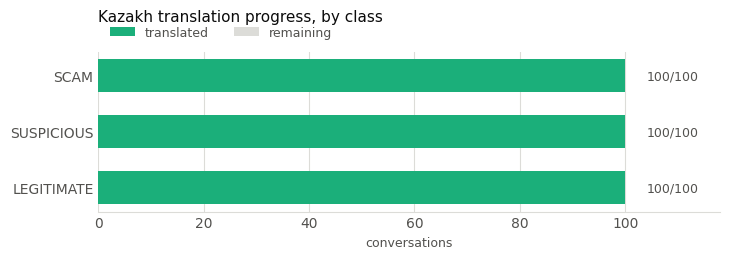

done,translated,remaining
label,,
LEGITIMATE,100,0
SUSPICIOUS,100,0
SCAM,100,0


In [11]:
progress = []
for source_path in sorted(translation.glob("batch_*_source.json")):
    target_path = source_path.with_name(source_path.name.replace("_source", "_kk"))
    convs = json.loads(source_path.read_text(encoding="utf-8"))
    for conv in convs:
        progress.append({"label": conv["label_3class"], "done": target_path.exists()})

prog = (pd.DataFrame(progress).groupby(["label", "done"]).size()
        .unstack(fill_value=0).reindex(CLASSES)
        .rename(columns={True: "translated", False: "remaining"}))
for column in ("translated", "remaining"):
    if column not in prog:
        prog[column] = 0
prog = prog[["translated", "remaining"]]

fig, ax = plt.subplots(figsize=(7.4, 2.7))
GAP = 1.2  # surface gap between stacked segments
left = [0] * len(prog)
for column, color in [("translated", AQUA), ("remaining", GRID)]:
    ax.barh(prog.index, prog[column], left=left, height=0.6, color=color, label=column)
    left = [a + b + GAP for a, b in zip(left, prog[column])]

for i, label in enumerate(prog.index):
    ax.text(104, i, f"{int(prog.loc[label, 'translated'])}/100",
            va="center", fontsize=9, color=MUTED)

ax.set_title("Kazakh translation progress, by class", loc="left", color=INK,
             fontsize=11, pad=22)
bare_axes(ax, "conversations")
ax.set_xlim(0, 118)
# above the plot, so it cannot collide with the bars or their end labels
ax.legend(frameon=False, ncol=2, labelcolor=MUTED, fontsize=9,
          loc="lower left", bbox_to_anchor=(0, 1.01))
plt.tight_layout()
plt.show()

prog

## 5. What came of this

Every item this notebook originally listed as "next" is now done, and the cells above are
the evidence rather than the plan:

1. **Renderings reconciled.** `scripts/translation_memory.py`, keyed on
   (string, style_variant). Drift within a style is 0; the 45 cross-style differences are
   register, kept on purpose.
2. **The remaining conversations translated** — 300/300, all fifteen batches passing
   `validate_translation.py`.
3. **Merged**, each Kazakh row carrying `language="kk"` and its source's split. The merge
   asserts that rule and fails if it is ever violated.

### What this notebook hands to the next one

`notebooks/02_feature_engineering.ipynb` depends on three results established here:

- **the label was derived from `decision_class` and `should_trigger_scam_defense`**
  (section 1) — which is precisely why notebook 02 has to audit *label* leakage before
  building a single feature, and why neither column may ever be an input;
- **the split rule** (section 3), which makes a train-English / evaluate-Kazakh
  comparison safe to run;
- **the 300 EN/KK pairs**, which let notebook 02 *measure* which features survive
  translation rather than assume it.

Still open after all of it: **no native speaker has reviewed the Kazakh for fluency.**
Everything verified here is structural.
